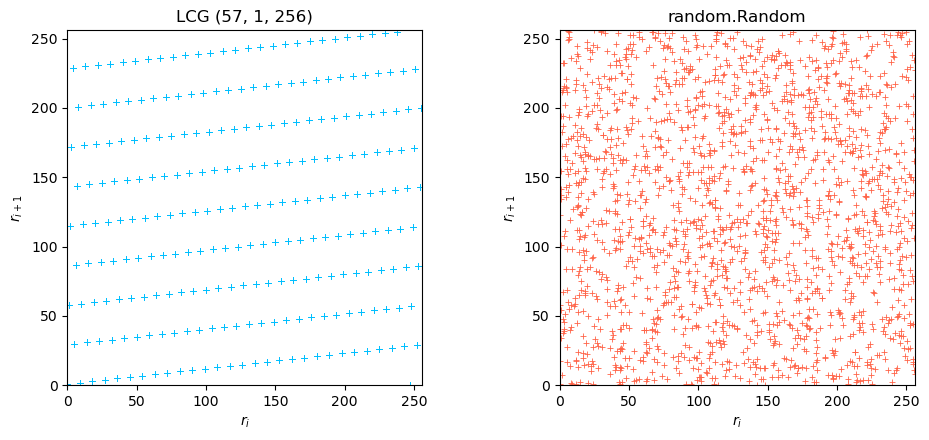

In [1]:
import random
import matplotlib.pyplot as plt

# --- Parámetros ---
N = 2000                  # número de pares
M = 256                   # escala de los ejes
semilla = 10

# --- LCG deficiente: r_{i+1} = (57*r_i + 1) mod 256 ---
r = semilla
x_lcg, y_lcg = [], []

for _ in range(N):
    siguiente = (57*r + 1) % M

    # Cada punto representa dos valores consecutivos.
    x_lcg.append(r)
    y_lcg.append(siguiente)

    r = siguiente

# --- Generador incorporado en Python ---
rng = random.Random(semilla)
anterior = M*rng.random()
x_python, y_python = [], []

for _ in range(N):
    siguiente = M*rng.random()

    x_python.append(anterior)
    y_python.append(siguiente)

    anterior = siguiente

# --- Comparación gráfica: puntos sin líneas que los conecten ---
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.5))

ejes[0].scatter(
    x_lcg, y_lcg,
    marker="+", s=25, linewidths=0.6, color="deepskyblue"
)
ejes[0].set_title("LCG (57, 1, 256)")

ejes[1].scatter(
    x_python, y_python,
    marker="+", s=25, linewidths=0.6, color="tomato"
)
ejes[1].set_title("random.Random")

for ax in ejes:
    ax.set_xlim(0, M)
    ax.set_ylim(0, M)
    ax.set_xlabel(r"$r_i$")
    ax.set_ylabel(r"$r_{i+1}$")
    ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("comparacion_generadores.png", dpi=200)
plt.show()

In [1]:
a = 13                         # 1101
b = 6                          # 0110
c = 10                         # 1010

# Máscaras: seleccionan los bits que queremos conservar.
y = (a & 0b1100) | (b & 0b0011)
desplazado = y >> 1
nuevo = c ^ desplazado         # ^ significa XOR

print(f"Combinación:    {y:04b} = {y}")
print(f"Desplazamiento: {desplazado:04b} = {desplazado}")
print(f"Nuevo valor:    {nuevo:04b} = {nuevo}")

Combinación:    1110 = 14
Desplazamiento: 0111 = 7
Nuevo valor:    1101 = 13


In [2]:
%%writefile ejemplo_mersenne.f90
module mersenne_twister
    use iso_fortran_env, only: int64, real64
    implicit none
    private
    public :: iniciar_mt, aleatorio_mt

    ! Estado: 624 palabras de 32 bits.
    ! Se almacenan en enteros de 64 bits para evitar overflow
    ! durante la inicialización.
    integer, parameter :: N = 624, M = 397
    integer(int64), save :: estado(0:N-1)
    integer, save :: indice = N
    logical, save :: inicializado = .false.

    ! Máscaras que seleccionan bits.
    integer(int64), parameter :: mascara32 = int(z'FFFFFFFF', int64)
    integer(int64), parameter :: superior  = int(z'80000000', int64)
    integer(int64), parameter :: inferior  = int(z'7FFFFFFF', int64)
    integer(int64), parameter :: matriz_a  = int(z'9908B0DF', int64)

contains

    subroutine iniciar_mt(semilla)
        integer(int64), intent(in) :: semilla
        integer :: i
        integer(int64) :: previo

        ! Construir todo el estado a partir de la semilla.
        estado(0) = iand(semilla, mascara32)

        do i = 1, N-1
            previo = ieor(estado(i-1), shiftr(estado(i-1), 30))
            estado(i) = iand(1812433253_int64*previo + &
                            int(i, int64), mascara32)
        end do

        indice = N
        inicializado = .true.
    end subroutine iniciar_mt


    subroutine renovar_estado()
        integer :: i
        integer(int64) :: y, mezcla

        ! Twist: combinar bits de estados vecinos y de otro
        ! estado situado a M posiciones.
        do i = 0, N-1
            y = ior(iand(estado(i), superior), &
                    iand(estado(modulo(i+1, N)), inferior))

            mezcla = shiftr(y, 1)

            ! Si y es impar, aplicar una transformación adicional.
            if (btest(y, 0)) mezcla = ieor(mezcla, matriz_a)

            estado(i) = ieor(estado(modulo(i+M, N)), mezcla)
        end do

        indice = 0
    end subroutine renovar_estado


    function aleatorio_mt() result(u)
        real(real64) :: u
        integer(int64) :: y

        ! Semilla por defecto si no se inicializó explícitamente.
        if (.not. inicializado) call iniciar_mt(5489_int64)
        if (indice >= N) call renovar_estado()

        y = estado(indice)
        indice = indice + 1

        ! Tempering: transformar los bits de la salida.
        ! IEOR es XOR; IAND es AND.
        y = ieor(y, shiftr(y, 11))
        y = ieor(y, iand(shiftl(y, 7),  int(z'9D2C5680', int64)))
        y = ieor(y, iand(shiftl(y, 15), int(z'EFC60000', int64)))
        y = ieor(y, shiftr(y, 18))
        y = iand(y, mascara32)

        ! Convertir el entero de 32 bits a un real en [0, 1).
        u = real(y, real64)/4294967296.0_real64
    end function aleatorio_mt

end module mersenne_twister


program ejemplo
    use iso_fortran_env, only: int64, real64
    use mersenne_twister, only: iniciar_mt, aleatorio_mt
    implicit none

    integer :: i
    real(real64) :: u

    ! Inicializar UNA vez, antes del ciclo.
    call iniciar_mt(5489_int64)

    do i = 1, 5
        u = aleatorio_mt()
        print '(F14.10)', u
    end do
end program ejemplo

Writing ejemplo_mersenne.f90


In [3]:
!gfortran -std=f2008 ejemplo_mersenne.f90 -o ejemplo_mersenne
!./ejemplo_mersenne

  0.8147236919
  0.1354770041
  0.9057919341
  0.8350085898
  0.1269868119
